# Activity 3: Colab–VS Code Bridge

**Question:** In a small synthetic set of card transactions, how do the transaction amount and the share of flagged transactions differ by hour of day?

**Data provenance:** The data are **synthetic**. They are generated inside this notebook with NumPy using a fixed random seed (`SEED = 42`). No real, personal, or institutional data are used.

**Expected output:** A summary table by time band (count, average amount, flagged share) and one bar chart.

**Dependencies:** Python 3, pandas, NumPy, and matplotlib (pre-installed in Google Colab; listed in `environment.yml` for local runs).

**Source of truth:** This file lives in GitHub (`itd-messilovers/capstone-projectHome`). Colab is only the runtime.

In [1]:
# Setup: print the environment and import only what this exercise needs.
# pandas, numpy and matplotlib come pre-installed in Google Colab.
# If running elsewhere and a package is missing, uncomment the next line:
# %pip install pandas numpy matplotlib

import sys
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
numpy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0


In [2]:
# Synthetic data: generated here with a fixed seed so every run is identical.
# These are NOT real transactions.
SEED = 42
rng = np.random.default_rng(SEED)

n = 500
hour = rng.integers(0, 24, size=n)
amount = np.round(rng.lognormal(mean=4.0, sigma=0.8, size=n), 2)

# Invented rule for illustration: night hours and larger amounts are flagged more often.
base_prob = np.where((hour < 6) | (hour >= 22), 0.08, 0.02)
flag_prob = np.clip(base_prob + (amount > 150) * 0.05, 0, 1)
flagged = rng.random(n) < flag_prob

df = pd.DataFrame({"hour": hour, "amount": amount, "flagged": flagged})
print(df.shape)
df.head()

(500, 3)


,hour,amount,flagged
0,2,50.63,False
1,18,13.38,False
2,15,16.88,False
3,10,299.88,True
4,10,19.49,False


Overall flagged share: 0.042


,transactions,avg_amount,flagged_share
time_band,,,
00-05 night,122,78.019,0.082
06-11 morning,134,65.272,0.030
12-17 afternoon,119,74.970,0.025
18-21 evening,82,79.357,0.024
22-23 night,43,65.139,0.047


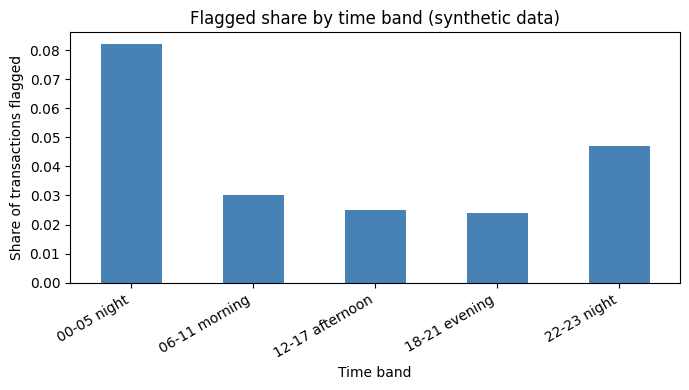

In [3]:
# Analysis: group transactions into time bands and summarize.
bins = [0, 6, 12, 18, 22, 24]
labels = ["00-05 night", "06-11 morning", "12-17 afternoon", "18-21 evening", "22-23 night"]
df["time_band"] = pd.cut(df["hour"], bins=bins, labels=labels, right=False)

summary = (
    df.groupby("time_band", observed=True)
      .agg(transactions=("amount", "size"),
           avg_amount=("amount", "mean"),
           flagged_share=("flagged", "mean"))
      .round(3)
)
print("Overall flagged share:", round(df["flagged"].mean(), 3))
display(summary)

ax = summary["flagged_share"].plot(kind="bar", figsize=(7, 4), color="steelblue")
ax.set_title("Flagged share by time band (synthetic data)")
ax.set_xlabel("Time band")
ax.set_ylabel("Share of transactions flagged")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Conclusion

- With the fixed seed (`SEED = 42`), the overall flagged share is about **4%**, and the **00-05 night** band has the highest flagged share (about **8%**), roughly three times the daytime bands.
- This pattern exists **because we built it into the synthetic data** (night hours and amounts above 150 have a higher invented flag probability). It shows how the notebook works; it is **not evidence about real fraud**.
- **Limitation:** 500 synthetic rows and an invented rule cannot support conclusions about real transactions.

**Reproducibility note:** This notebook was run from a clean Google Colab runtime opened from GitHub. The saved file keeps the code and outputs, but **not** the runtime: installed packages, variables in memory, and local files are not shared. Anyone re-running it needs a fresh session and the packages listed in the setup cell.